<script src="/course_model/toc.js"></script>

# Natural Language Processing (NLP) with Python

Natural Language Processing (NLP) teaches computers to work with text. NLP turns messy text (course comments, survey responses, reviews, emails) into numbers you can model.

**Outcomes**:
- Explain what NLP does in a data analysis workflow
- Load and explore a small text dataset in IPython
- Clean and preprocess raw text (lowercasing, removing punctuation, stopwords)
- Turn text into numeric features using TF-IDF
- Build and evaluate a simple text classifier
- Do a basic unsupervised topic exploration with clustering and PCA

**Examples**:
- [db of happiness](https://github.com/megagonlabs/HappyDB)
- [Vis](https://flowingdata.com/2021/07/29/counting-happiness/)
- [Vis2](https://flowingdata.com/2018/06/21/what-makes-people-the-most-happy/)
- [Vis3](https://pudding.cool/2026/02/happy-map/)

**Links**:
- [newsgroup template](newsgroup.ipynb) 
- [template](template.ipynb) and [datafile](sms_spam.csv)

## Algorithm Overview

Key Concepts:
- NLP turns text into numbers for modeling.
- Each piece of text being analyzed (a comment, a review, an email) is called a document. The full collection of documents is the corpus.
- Tokenization splits each document into individual words, called tokens. The set of unique words across all documents is the vocabulary.
- Text requires preprocessing 
    - Lowercasing and removing punctuation are easy methods for removing noise.
    - Stopwords (commonly used words like "the", "and", "is") are often removed to reduce noise.
- TF-IDF is a common method to convert text into tables of numbers (one row per document, one column per word).
    - TF-IDF weights words by importance, reducing the impact of common words. This is often better for modeling.
- NLP can be used for supervised and unsupervised learning
    - Supervised models may include building a classifier with logistic regression to predict spam vs. non-spam emails.
    - Unsupervised models may include clustering documents to find topics.

Problems:
- Text data is often messy and unstructured, requiring significant preprocessing.
- High dimensionality: Text data can lead to a large number of features (words), which can complicate modeling. The resulting table is also sparse (mostly zeros), because each document uses only a few of the words in the vocabulary.
- Context and semantics: Capturing the meaning of words and phrases can be challenging, especially with polysemy (words with multiple meanings) and synonyms.
- Computational resources: Processing large text datasets can be resource-intensive.

Interpretation:
- Overall model:
    - For supervised learning, we can evaluate model performance using metrics like accuracy, precision, recall, and F1-score for classification tasks.
    - For unsupervised learning, we can assess clustering quality using metrics like inertia.

### Step 1: Sample Course Evaluation

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 4)

data = [
    ("The assignments were really helpful and the examples were clear.", 1),
    ("Too much homework and unclear instructions on most projects.", 0),
    ("I loved the real-world data sets we used in class.", 1),
    ("Lectures were disorganized and it was hard to follow.", 0),
    ("Great balance of theory and practice, very engaging instructor.", 1),
    ("The grading rubric was confusing and feedback was limited.", 0),
    ("I learned a lot about Python and data analysis in this course.", 1),
    ("The pace was too fast and slides were not posted on time.", 0),
    ("Very practical course, I feel more confident analyzing data.", 1),
    ("Group project instructions were vague and deadlines were unrealistic.", 0),
    ("The examples made complex ideas much easier to understand.", 1),
    ("Instructions for several assignments were unclear and hard to follow.", 0),
    ("I appreciated the real-life applications woven into each lecture.", 1),
    ("The workload felt excessive compared to other courses at this level.", 0),
    ("The instructor explained things clearly and supported us well.", 1),
    ("Deadlines were too close together and caused unnecessary stress.", 0),
    ("Class discussions were engaging and helped reinforce key concepts.", 1),
    ("It was difficult to know what was expected on the midterm.", 0),
    ("Great mix of coding demonstrations and conceptual teaching.", 1),
    ("The slides were often posted late, making it hard to prepare.", 0),
    ("I really liked how approachable the instructor was.", 1),
    ("A lot of confusing grading standards across assignments.", 0),
    ("The projects were challenging in a good way and taught me a lot.", 1),
    ("Course expectations shifted too often and caused confusion.", 0),
    ("I liked the hands-on approach to learning Python.", 1),
    ("Feedback took too long to return and wasn’t very detailed.", 0),
    ("Loved the interactive notebooks used in class!", 1),
    ("The textbook was outdated and not helpful.", 0),
    ("Office hours were extremely helpful for understanding tricky topics.", 1),
    ("Some quizzes covered material we never discussed.", 0),
    ("Great pacing and very clear explanations.", 1),
    ("The instructor talked too fast and skipped important steps.", 0),
    ("Assignments pushed me to think critically and apply what I learned.", 1),
    ("Too many last-minute announcements made planning difficult.", 0),
    ("I enjoyed the practical examples involving real datasets.", 1),
    ("Group work was disorganized and uneven across teams.", 0),
    ("The instructor encouraged questions and created a welcoming environment.", 1),
    ("Lecture recordings were frequently missing or incomplete.", 0),
    ("Clear expectations and fair grading throughout the course.", 1),
    ("The project instructions were vague and frustrating.", 0),
    ("Very supportive instructor who wanted us to succeed.", 1),
    ("Assignments were overloaded with unnecessary steps.", 0),
    ("Class activities helped me retain the material better.", 1),
    ("The exam format didn’t match what we practiced in class.", 0),
    ("I learned to write better code because of this course.", 1),
    ("Several assignments required tools we never covered.", 0),
    ("The instructor broke concepts down into manageable pieces.", 1),
    ("The lecture slides were poorly formatted and hard to read.", 0),
    ("Great environment for building confidence in data analysis.", 1),
    ("Class often felt rushed and lacked structure.", 0),
    ("The examples were relevant and connected well to real problems.", 1),
    ("The grading rubric was not followed consistently.", 0),
    ("The course helped me feel more capable analyzing data.", 1),
    ("There were frequent technical issues during lectures.", 0),
    ("The instructor used humor and stories that made class enjoyable.", 1),
    ("Assignments required too much time for the number of credits.", 0),
    ("Material was explained step-by-step and easy to follow.", 1),
    ("Course organization was confusing and inconsistent.", 0),
    ("Hands-on labs were the best part of this class.", 1),
    ("The final exam felt unfair and didn’t reflect what we learned.", 0),
    ("I liked how the instructor connected Python to real careers.", 1),
    ("Syllabus didn’t match what happened during the semester.", 0),
    ("The instructor checked in often to make sure we understood.", 1),
    ("Poor communication about changes to deadlines.", 0),
    ("Amazing job making complex topics feel intuitive.", 1),
    ("Too many required platforms and tools to keep track of.", 0),
    ("The coding demos were clear and easy to replicate.", 1),
    ("The rubric never explained how partial credit was assigned.", 0),
    ("Very motivating instructor who clearly cared.", 1),
    ("The homework system didn’t save progress reliably.", 0),
    ("The course tied theory and application together well.", 1),
    ("Daily logistics like attendance and make-ups were unclear.", 0),
    ("Great examples that helped solidify the material.", 1),
    ("Lectures often went off-topic and wasted time.", 0),
    ("I gained meaningful, practical skills from this class.", 1),
    ("It was hard to know what material would be on the quizzes.", 0),
    ("The instructor gave helpful, specific feedback.", 1),
    ("The workload was inconsistent from week to week.", 0),
    ("I appreciated the supportive classroom environment.", 1),
    ("Recordings were unreliable and cut off mid-lecture.", 0),
    ("The interactive coding sessions were very useful.", 1),
    ("Many tasks felt repetitive rather than educational.", 0),
    ("The course helped me become confident writing Python code.", 1),
    ("Deadlines were scheduled at unreasonable times.", 0),
    ("The instructor’s explanations made everything make sense.", 1),
    ("Important announcements were easy to miss.", 0),
    ("The design of the projects helped me understand the material deeply.", 1),
    ("Class often started late and felt unprepared.", 0),
    ("The mix of theory and hands-on work was excellent.", 1),
    ("The grading process felt random and inconsistent.", 0),
    ("Good pacing, and the instructor checked for understanding often.", 1),
    ("Assignments required tools not supported on my computer.", 0),
    ("This was one of the most practical courses I've taken.", 1),
    ("There was little explanation about how grades were computed.", 0),
    ("Clear lectures with helpful real-world examples.", 1),
    ("Homework feedback did not explain what to improve.", 0),
    ("The instructor made time for every student who needed help.", 1),
    ("The LMS was disorganized with missing files.", 0),
]

df = pd.DataFrame(data, columns=["comment", "sentiment"])  # 1=positive, 0=negative
df


,comment,sentiment
0,The assignments were really helpful and the ex...,1
1,Too much homework and unclear instructions on ...,0
2,I loved the real-world data sets we used in cl...,1
3,Lectures were disorganized and it was hard to ...,0
4,"Great balance of theory and practice, very eng...",1
...,...,...
93,There was little explanation about how grades ...,0
94,Clear lectures with helpful real-world examples.,1
95,Homework feedback did not explain what to impr...,0
96,The instructor made time for every student who...,1


### Step 2: Data Cleanup

NLP usually starts with normalizing the text:

- Lowercasing (“The” and “the” become the same)
- Removing punctuation
- Optionally removing stopwords (“and”, “the”, “of”)
- Optionally stemming/lemmatizing (turning “running”, “runs” → “run”)

Here we do this in two parts:
- A small function of our own lowercases the text and removes punctuation.
- Later, scikit-learn’s `TfidfVectorizer` handles tokenization (splitting text into words) and removes English stopwords when we ask it to.

In [2]:
import re

def basic_clean(text: str) -> str:
    # Lowercase
    text = text.lower()
    # Remove anything that's not a letter or space
    text = re.sub(r"[^a-z\s]", "", text)
    # Collapse multiple spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_comment"] = df["comment"].apply(basic_clean)
df[["comment", "clean_comment"]]

,comment,clean_comment
0,The assignments were really helpful and the ex...,the assignments were really helpful and the ex...
1,Too much homework and unclear instructions on ...,too much homework and unclear instructions on ...
2,I loved the real-world data sets we used in cl...,i loved the realworld data sets we used in class
3,Lectures were disorganized and it was hard to ...,lectures were disorganized and it was hard to ...
4,"Great balance of theory and practice, very eng...",great balance of theory and practice very enga...
...,...,...
93,There was little explanation about how grades ...,there was little explanation about how grades ...
94,Clear lectures with helpful real-world examples.,clear lectures with helpful realworld examples
95,Homework feedback did not explain what to impr...,homework feedback did not explain what to improve
96,The instructor made time for every student who...,the instructor made time for every student who...


### Step 3: TF-IDF – focus on informative words

A simpler approach, called Bag-of-Words, just counts how many times each word appears in each document. This treats all words equally. TF-IDF (Term Frequency–Inverse Document Frequency) down-weights very common words and up-weights words that are more distinctive. 

Intuition:
- “course” might appear in almost every comment → not very informative.
- “disorganized” or “engaging” appear less often → more informative signals.

Example:

Documents:

- “Course is great”
- “Course is hard”
- “Course is hard”
- “Wow”

Vocabulary used: course, great, hard, wow ("is" is a stopword, so it is removed)

*Count matrix:*

| Document        | course | great | hard | wow |
| --------------- | ------ | ----- | ---- | --- |
| Course is great | 1      | 1     | 0    | 0   |
| Course is hard  | 1      | 0     | 1    | 0   |
| Course is hard  | 1      | 0     | 1    | 0   |
| Wow             | 0      | 0     | 0    | 1   |


*TF-IDF matrix:*


| Document        | course | great | hard  | wow   |
| --------------- | ------ | ----- | ----- | ----- |
| Course is great | 0.538  | 0.843 | 0.000 | 0.000 |
| Course is hard  | 0.629  | 0.000 | 0.777 | 0.000 |
| Course is hard  | 0.629  | 0.000 | 0.777 | 0.000 |
| Wow             | 0.000  | 0.000 | 0.000 | 1.000 |

These are the values scikit-learn's `TfidfVectorizer` produces, rounded for readability. The pattern is what's important: "course" appears in three of the four documents, so it gets a lower weight than "great" (one document) or "hard" (two documents).




In [3]:
# Turn every cleaned comment into a row of TF-IDF values
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
X_tfidf = tfidf_vectorizer.fit_transform(df["clean_comment"])

# One row per comment, one column per word in the vocabulary
print("Rows (comments) and columns (words):", X_tfidf.shape)
print("First 10 words in the vocabulary:", list(tfidf_vectorizer.get_feature_names_out()[:10]))

Rows (comments) and columns (words): (98, 283)
First 10 words in the vocabulary: ['activities', 'amazing', 'analysis', 'analyzing', 'announcements', 'application', 'applications', 'apply', 'appreciated', 'approach']


### Step 4: Build and evaluate a classifier

Now we use the TF-IDF features in a supervised model: a logistic regression that predicts whether a comment is positive (1) or negative (0).

We split the comments into training and test sets before fitting the vectorizer. The vocabulary and word weights are learned from the training comments only and then applied to the test comments. Fitting the vectorizer on all of the comments first would be data leakage: information from the test set would shape the features, making the test results look better than they should.

In the results below, the model is perfect on the training set but gets about 87% of the test comments right. That gap is a sign of overfitting, which is expected here: there are far more word columns than training comments, so the model can memorize the training set.

Training accuracy: 1.0
Test accuracy: 0.8666666666666667


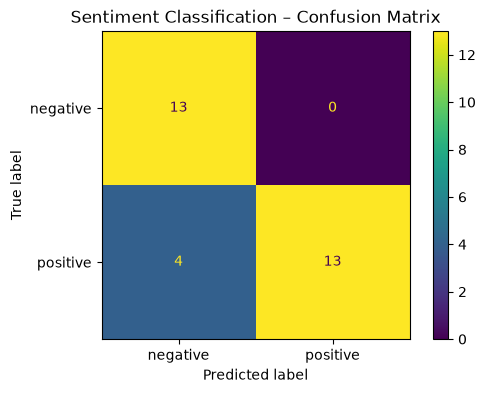

In [4]:
# Split the comments first, so the test comments stay unseen
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_comment"], df["sentiment"], test_size=0.3, random_state=42
)

# Learn the vocabulary and word weights from the training comments only,
# then apply them to the test comments
clf_vectorizer = TfidfVectorizer(stop_words="english")
X_train = clf_vectorizer.fit_transform(X_train_text)
X_test = clf_vectorizer.transform(X_test_text)

# Fit a logistic regression to predict sentiment from the TF-IDF features
clf_tfidf = LogisticRegression(max_iter=1000)
clf_tfidf.fit(X_train, y_train)

# How well does it do on the training set?
y_train_pred = clf_tfidf.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred)
print(f"Training accuracy: {train_acc}")

# How well does it do on the *test* set?
y_pred = clf_tfidf.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_acc}")

# Confusion Matrix for test set
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["negative", "positive"])
disp.plot()
plt.title("Sentiment Classification – Confusion Matrix")
plt.show()


### Step 5: Clustering to explore topics

What if you don’t have labels?
You can still use NLP to group documents with similar content.

We’ll use K-Means clustering on the TF-IDF matrix:
- Input: TF-IDF features for all of the comments
- Output: Cluster assignments (e.g., “complaints about workload” vs “praise for instructor”)

Unlike the earlier K-Means lesson, we do not use `StandardScaler` here. TF-IDF values are already on a common scale, so no single word dominates the distances.

To see what each cluster is about, we print the words with the highest weights in each cluster's center.

In [5]:
k = 2  # we suspect there might be "positive" vs "negative"-like groups
kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
clusters = kmeans.fit_predict(X_tfidf)

df["cluster"] = clusters
df[["comment", "cluster"]]


,comment,cluster
0,The assignments were really helpful and the ex...,0
1,Too much homework and unclear instructions on ...,1
2,I loved the real-world data sets we used in cl...,0
3,Lectures were disorganized and it was hard to ...,0
4,"Great balance of theory and practice, very eng...",0
...,...,...
93,There was little explanation about how grades ...,0
94,Clear lectures with helpful real-world examples.,0
95,Homework feedback did not explain what to impr...,0
96,The instructor made time for every student who...,0


In [6]:
terms = tfidf_vectorizer.get_feature_names_out()
centers = kmeans.cluster_centers_

for cluster_id in range(k):
    print(f"\nCluster {cluster_id}")
    center = centers[cluster_id]
    top_idx = center.argsort()[::-1][:10]
    print([terms[i] for i in top_idx])

print("\nComments per cluster:")
print(df["cluster"].value_counts().sort_index())


Cluster 0
['instructor', 'class', 'course', 'assignments', 'material', 'examples', 'felt', 'helped', 'clear', 'helpful']

Cluster 1
['unclear', 'instructions', 'projects', 'homework', 'follow', 'hard', 'makeups', 'attendance', 'logistics', 'daily']

Comments per cluster:
cluster
0    95
1     3
Name: count, dtype: int64


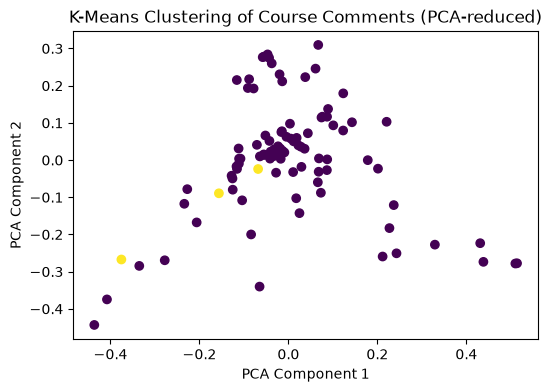

Share of variance explained by the two components: 0.05194926550628682


In [7]:
# Visualize clusters using PCA (2D)
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_tfidf.toarray())
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis')
plt.title("K-Means Clustering of Course Comments (PCA-reduced)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

print("Share of variance explained by the two components:", pca.explained_variance_ratio_.sum())

In these results, the two clusters did not split into positive and negative comments. One cluster holds almost every comment, and the other holds a handful of comments that share words like "unclear" and "instructions". K-Means groups documents by the words they share, not by their sentiment, and 98 short comments give it little to work with.

The PCA plot should also be read with care. Two components capture only about 5% of the variance in the TF-IDF matrix, because the information is spread across hundreds of word columns. The plot is a rough picture, not a faithful map of the data.

## Key Terms

- **Natural Language Processing (NLP)**: Methods that teach computers to work with text by turning it into numbers that can be modeled
- **Document**: One unit of text being analyzed, such as a single comment, review, or email
- **Corpus**: The full collection of documents being analyzed
- **Token**: A single piece of text, usually a word, produced by splitting a document
- **Tokenization**: Splitting text into individual words
- **Vocabulary**: The set of unique words found across all of the documents; each one becomes a column
- **Preprocessing (text)**: Cleaning raw text before modeling, such as lowercasing and removing punctuation
- **Lowercasing**: Converting all text to lowercase so that "The" and "the" are treated as the same word
- **Stopwords**: Very common words such as "the", "and", and "is" that are often removed to reduce noise
- **Stemming / lemmatizing**: Reducing related words such as "running" and "runs" to a common base form, "run"
- **Bag-of-Words**: Representing each document by how many times each word appears, ignoring word order
- **Count matrix**: A table with one row per document and one column per word, holding word counts
- **TF-IDF**: Term Frequency–Inverse Document Frequency; a weighting that down-weights very common words and up-weights distinctive ones
- **Term frequency (TF)**: How often a word appears in a single document
- **Inverse document frequency (IDF)**: A weight that is larger for words appearing in few documents and smaller for words appearing in many
- **High dimensionality**: Having a very large number of features, such as one column for every word in the vocabulary
- **Sparse matrix**: A table that is mostly zeros, because each document uses only a few of the words in the vocabulary
- **Text classifier**: A supervised model that predicts a category for a document, such as spam or positive sentiment
- **Sentiment analysis**: Classifying text by the attitude it expresses, such as positive or negative
- **Data leakage**: When information from the test set is used while building the model, making test results look better than they should
- **Topic exploration**: Using unsupervised methods such as clustering to find groups of documents with similar content
- **Polysemy**: A single word having multiple meanings, which makes text harder to model


## Practice Questions

1. What does NLP do in a data analysis workflow?
   - Turns messy text into numbers that can be modeled
   - Removes outliers from numeric columns
   - Converts numbers into written reports
   - Splits a dataset into training and test sets
1. Why do we lowercase text before modeling?
   - So that "The" and "the" are treated as the same word
   - So the text takes up less storage
   - Because models cannot read capital letters
   - To remove the stopwords
1. What are stopwords?
   - Very common words like "the", "and", and "is" that carry little meaning
   - Words that appear only once in the dataset
   - Words that end a sentence
   - Misspelled words
1. What does tokenization do?
   - Splits text into individual words
   - Converts words to lowercase
   - Removes the most common words
   - Counts the number of documents
1. What does stemming or lemmatizing do?
   - Reduces related words like "running" and "runs" to a common base form
   - Removes punctuation from the text
   - Translates the text into another language
   - Sorts the words alphabetically
1. In a TF-IDF matrix, what do the rows and columns represent?
   - One row per document and one column per word
   - One row per word and one column per letter
   - One row per sentence and one column per document
   - One row per cluster and one column per topic
1. How does TF-IDF differ from simple word counts?
   - It down-weights words that appear in most documents and up-weights distinctive words
   - It counts every word equally
   - It only keeps the first word of each document
   - It removes all words longer than five letters
1. The word "course" appears in almost every course comment. How does TF-IDF treat it?
   - It gets a low weight, because it does little to tell the comments apart
   - It gets the highest weight, because it is the most frequent word
   - It is automatically converted to a stopword and removed
   - It gets the same weight as every other word
1. In the example, the document "Course is great" has a TF-IDF of 0.538 for "course" and 0.843 for "great". Why is "great" higher?
   - "great" appears in only one document, while "course" appears in three
   - "great" has more letters than "course"
   - "great" comes later in the sentence
   - "great" appears more times within that document
1. Why does the word "is" not appear in the example's vocabulary?
   - It is a stopword and was removed
   - It is too short to count as a word
   - It only appears once
   - It was removed with the punctuation
1. Our 98 course comments produce a TF-IDF matrix with 283 columns. What problem does this illustrate?
   - High dimensionality: text creates far more features than a typical dataset
   - Missing values in the comments
   - Too few documents to tokenize
   - Outliers in the sentiment column
1. Why is a TF-IDF matrix mostly zeros?
   - Each document uses only a few of the words in the vocabulary
   - Stopwords are stored as zeros
   - TF-IDF rounds small values down to zero
   - The comments were lowercased
1. Which is an example of supervised learning with text?
   - Predicting whether an email is spam or not spam
   - Grouping comments into clusters to explore topics
   - Removing stopwords from comments
   - Reducing TF-IDF columns with PCA
1. Why do we split the comments into training and test sets before fitting the TF-IDF vectorizer?
   - So the vocabulary and word weights are learned only from the training comments, avoiding data leakage
   - Because TF-IDF cannot be run on more than 70 documents
   - So the test set gets a larger vocabulary
   - To remove the stopwords from the test set
1. Our classifier scores 1.00 on the training set and about 0.87 on the test set. What does this suggest?
   - Some overfitting, which is expected with far more word columns than comments
   - The model is underfit
   - The test set is too easy
   - The data was not lowercased
1. The test set has 30 comments and the model predicts 26 correctly. What is the test accuracy?
   - About 0.87
   - 0.26
   - About 0.30
   - 1.00
1. In our confusion matrix, 4 positive comments were predicted as negative and no negative comments were predicted as positive. What is the recall for positive comments, given 17 actual positives?
   - About 0.76, because 13 of the 17 were found
   - 1.00
   - About 0.24
   - About 0.87
1. What can you do with text when you have no labels?
   - Use clustering to group documents with similar content
   - Train a logistic regression to predict sentiment
   - Calculate accuracy on a test set
   - Build a confusion matrix
1. How do we interpret what a K-Means cluster of comments is about?
   - Look at the words with the highest weights in the cluster's center
   - Look at the cluster's number
   - Count the punctuation in its comments
   - Check the accuracy of the cluster
1. We asked K-Means for 2 clusters and got one with 95 comments and one with 3. What does this tell you?
   - The clusters did not split into positive and negative; clustering finds groups by shared words, not by sentiment
   - K-Means failed and should be given the sentiment labels
   - 95 of the comments are positive
   - The comments must be standardized with `StandardScaler`
1. Why do we use PCA before plotting the clusters?
   - To reduce hundreds of word columns down to two that can be graphed
   - To improve the accuracy of the classifier
   - To remove stopwords
   - To choose the number of clusters
1. What is polysemy, and why is it a problem for NLP?
   - A word having multiple meanings, which makes it hard to capture what the text means
   - A document having multiple authors, which makes it hard to label
   - A dataset having multiple languages, which prevents tokenization
   - A word appearing in every document, which gives it a high TF-IDF